# This notebook is used for EDA of the data


Note that LLMs plus Google were heavily relied on for the early EDA. I've never used audio data before so much of this notebook is me learning about audio concepts for the first time. I try to synthesize any definitions in order to have a better understanding

## Imports

In [1]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt



## Load a single file and analyze

In [2]:
# Load audio file
file_path = "data/dementia/Robin Williams/RobinWilliams_0.wav"

audio, sample_rate = librosa.load(file_path, sr=None)

print(f"Sample rate: {sample_rate} Hz")
print(f"Audio duration: {len(audio) / sample_rate:.2f} seconds")
print(f"Number of samples: {len(audio)}")

c:\Users\nicol\OneDrive\Desktop\UT Masters\AI in Healthcare\dementia_prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sample rate: 44100 Hz
Audio duration: 86.01 seconds
Number of samples: 3792896


### Plot the wave form

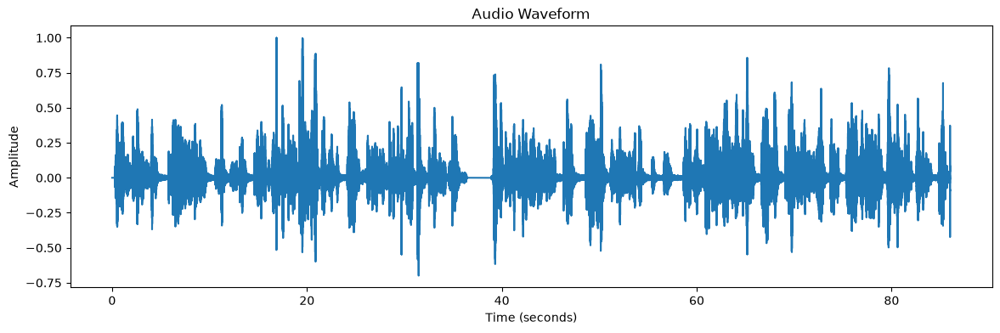

In [3]:
plt.figure(figsize=(14, 4))

time = np.arange(len(audio)) / sample_rate

plt.plot(time, audio)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Audio Waveform")
plt.show()

## You can play the audio in a notebook!!

In [4]:
from IPython.display import Audio, display

display(Audio(audio, rate=sample_rate))

## Some basic features of audio files

RMS is basically how loud the audio is

ZCR is how many times the frequency of the signal crosses zero. Higher represents a 'noisier' higherpitched signal

Spectral centroid is similar to center of mass of a sound's freq spectrum. Higher vals mean much of the sound's energy are in higher frequencies

MFCCs (mel freq cepstral coef) is set of numerical features that rep the overal spectral shape of an audio signal. This basically mimics how humans perceive sound. Can be thought of as a fingerprint of the sound

In [5]:
# Root Mean Square (RMS) energy
rms = librosa.feature.rms(y=audio)

# Zero crossing rate
zcr = librosa.feature.zero_crossing_rate(y=audio)

# Spectral centroid
spectral_centroid = librosa.feature.spectral_centroid(
    y=audio,
    sr=sample_rate
)

# Mel-frequency cepstral coefficients (MFCCs)
mfccs = librosa.feature.mfcc(
    y=audio,
    sr=sample_rate,
    n_mfcc=13
)

print("RMS shape:", rms.shape)
print("ZCR shape:", zcr.shape)
print("Spectral centroid shape:", spectral_centroid.shape)
print("MFCC shape:", mfccs.shape)

RMS shape: (1, 7409)
ZCR shape: (1, 7409)
Spectral centroid shape: (1, 7409)
MFCC shape: (13, 7409)


Spectrogram is used to show how the frequency content of the audio changes over time.

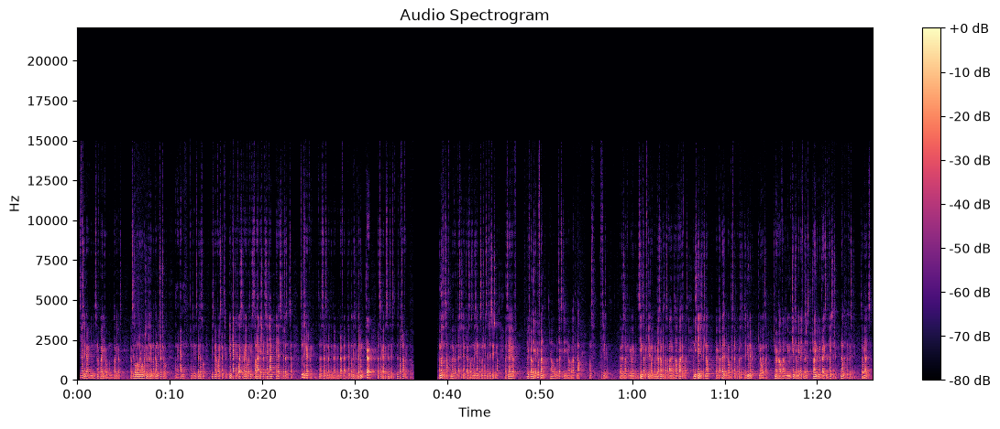

In [6]:
D = librosa.stft(audio)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    S_db,
    sr=sample_rate,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Audio Spectrogram")
plt.show()

In [7]:
features = {}

features["rms_mean"] = np.mean(rms)
features["rms_std"] = np.std(rms)

features["zcr_mean"] = np.mean(zcr)
features["zcr_std"] = np.std(zcr)

features["spectral_centroid_mean"] = np.mean(spectral_centroid)
features["spectral_centroid_std"] = np.std(spectral_centroid)

for i in range(mfccs.shape[0]):
    features[f"mfcc_{i+1}_mean"] = np.mean(mfccs[i])
    features[f"mfcc_{i+1}_std"] = np.std(mfccs[i])

print(features)

{'rms_mean': np.float32(0.04826826), 'rms_std': np.float32(0.043392673), 'zcr_mean': np.float64(0.03413935437474693), 'zcr_std': np.float64(0.035523138487741496), 'spectral_centroid_mean': np.float64(1557.0357769927407), 'spectral_centroid_std': np.float64(1055.4034360488045), 'mfcc_1_mean': np.float32(-326.00513), 'mfcc_1_std': np.float32(75.19919), 'mfcc_2_mean': np.float32(166.95073), 'mfcc_2_std': np.float32(50.72847), 'mfcc_3_mean': np.float32(14.974357), 'mfcc_3_std': np.float32(24.54268), 'mfcc_4_mean': np.float32(9.581088), 'mfcc_4_std': np.float32(26.536177), 'mfcc_5_mean': np.float32(4.8187475), 'mfcc_5_std': np.float32(17.021152), 'mfcc_6_mean': np.float32(18.00252), 'mfcc_6_std': np.float32(13.660236), 'mfcc_7_mean': np.float32(4.9868464), 'mfcc_7_std': np.float32(11.563011), 'mfcc_8_mean': np.float32(-5.7142115), 'mfcc_8_std': np.float32(7.7262263), 'mfcc_9_mean': np.float32(-8.090791), 'mfcc_9_std': np.float32(9.44497), 'mfcc_10_mean': np.float32(-7.785738), 'mfcc_10_std'

## Translate to text

This works really well. It misses some of his stutters, and doesn't pick up Mississippi correctly, but broadly does a really good job!

We can transcribe the audio files to get additional context about the complexity of what was said in addition to how it was said 

In [15]:
from faster_whisper import WhisperModel

# Initialize model
model = WhisperModel(
    "base",
    device="cuda",
    compute_type="int8"
)

# Transcribe audio NOTE!!! YOu have to have av version at <19 for this to work
segments, info = model.transcribe(
    file_path,
    beam_size=5
)

# Combine transcript segments
transcript = ""

for segment in segments:
    transcript += segment.text + " "

print("Language:", info.language)
print("Transcript:", transcript)

Language: en
Transcript:  He's a fascinating guy. I mean, he's kind of a quiet ego among large egos.  That was his whole role during World War II, dealing with Montgomery, Churchill.  Oh my god, Patton. But he's also a kind of a quiet strength, too.  Even capturing his voice is very difficult, I think, because it's somewhat high-pitched,  but at the same time, it has resonance. So, it's an interesting character for me.  It's not necessarily somebody who thinks that I write off the bat, be playing.  A lot of people say, you could play Truman. Sure.  But it's like, it was a tough job for me.  My mother's from the South, my mother grew up in Paschristian,  which I thought wasn't Louisiana until someone told me,  that's Mrs. Sipis, we talked.  But it's the idea of, and we talked about with Lee, that people forgotten  how what it was like 60, you know, or like now almost 50 years ago,  that what it is like. It seems like 50 years ago,  but you realize how intense it was, how violent it was,